# Retail Sales Prediction ML Project
End-to-end project on EDA, preprocessing, regression, and classification.

#### **1. Import libraries**

In [2]:
# data handling
# model saving 
import joblib

# visualization
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

# preprocessing
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.ensemble import (
    AdaBoostClassifier,
    AdaBoostRegressor,
    GradientBoostingClassifier,
    GradientBoostingRegressor,
    RandomForestClassifier,
    RandomForestRegressor,
)

# feature selection 
from sklearn.feature_selection import RFE, SelectKBest, VarianceThreshold, chi2
from sklearn.impute import SimpleImputer

# regression models
# classification models
from sklearn.linear_model import Lasso, LinearRegression, LogisticRegression, Ridge

# Metrics
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    mean_absolute_error,
    mean_squared_error,
    precision_score,
    r2_score,
    recall_score,
)

# Hyperparameter tuning
from sklearn.model_selection import (
    GridSearchCV,
    RandomizedSearchCV,
    cross_val_score,
    train_test_split,
)
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    MinMaxScaler,
    OneHotEncoder,
    StandardScaler,
)
from sklearn.svm import SVC, SVR
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from xgboost import XGBClassifier, XGBRegressor

#### **2. Load dataset**

In [3]:
df = pd.read_csv("shipping_data_with_outliers.csv")

#### **3. Basic EDA**

In [4]:
df.head()

,Category,Price,Rating,Stock,Discount,Shipping_weight
0,NaN,5548.0,1.870322,NaN,0.0,4500.000
1,NaN,3045.0,4.757798,NaN,38.0,12.000
2,NaN,4004.0,NaN,In Stock,0.0,5200.000
3,NaN,4808.0,1.492085,NaN,33.0,657.514
4,NaN,1817.0,NaN,Out of Stock,23.0,355.031


In [5]:
df.tail()

,Category,Price,Rating,Stock,Discount,Shipping_weight
4357,NaN,4436.0,4.728335,NaN,49.0,377.848
4358,B,6236.0,NaN,Out of Stock,4.0,581.377
4359,NaN,3283.0,NaN,Out of Stock,9.0,852.155
4360,D,2999.0,4.425995,NaN,40.0,599.991
4361,NaN,NaN,2.184471,NaN,0.0,711.088


In [6]:
df.sample(5)

,Category,Price,Rating,Stock,Discount,Shipping_weight
940,NaN,1557.0,1.635867,In Stock,23.0,901.817
4029,A,2056.0,1.559805,Out of Stock,NaN,450.157
2122,C,857.0,NaN,Out of Stock,5.0,835.985
686,NaN,4650.0,3.363035,In Stock,3.0,270.315
1560,NaN,NaN,3.486367,In Stock,32.0,257.900


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4362 entries, 0 to 4361
Data columns (total 6 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Category         1614 non-null   str    
 1   Price            4188 non-null   float64
 2   Rating           2312 non-null   float64
 3   Stock            3010 non-null   str    
 4   Discount         3970 non-null   float64
 5   Shipping_weight  4362 non-null   float64
dtypes: float64(4), str(2)
memory usage: 236.6 KB


In [8]:
df.describe()

,Price,Rating,Discount,Shipping_weight
count,4188.000000,2312.000000,3970.000000,4362.000000
mean,5016.970630,3.038293,24.516625,550.511660
std,2839.984813,1.143074,14.347164,276.821159
min,102.000000,1.000366,0.000000,12.000000
25%,2628.250000,2.069490,12.000000,323.872750
50%,4996.500000,3.082060,25.000000,550.736000
75%,7418.000000,4.008620,37.000000,772.895750
max,9999.000000,4.997818,49.000000,5200.000000


In [9]:
print("Memory Usage:\n", df.memory_usage())

Memory Usage:
 Index                132
Category           37056
Price              34896
Rating             34896
Stock              65510
Discount           34896
Shipping_weight    34896
dtype: int64


In [10]:
print("Unique Values:\n", df.nunique())

Unique Values:
 Category              4
Price              3422
Rating             2312
Stock                 2
Discount             50
Shipping_weight    4350
dtype: int64


In [11]:
print("Columns:", df.columns)

Columns: Index(['Category', 'Price', 'Rating', 'Stock', 'Discount', 'Shipping_weight'], dtype='str')


In [12]:
print('shape: ',df.shape)

shape:  (4362, 6)


In [13]:
df.dtypes

Category               str
Price              float64
Rating             float64
Stock                  str
Discount           float64
Shipping_weight    float64
dtype: object

In [14]:
print("Missing Values:\n", df.isnull().sum())

Missing Values:
 Category           2748
Price               174
Rating             2050
Stock              1352
Discount            392
Shipping_weight       0
dtype: int64


In [15]:
print("Duplicates:", df.duplicated().sum())

Duplicates: 0


#### **4. Visualization Analysis**

**1. univariate analysis**

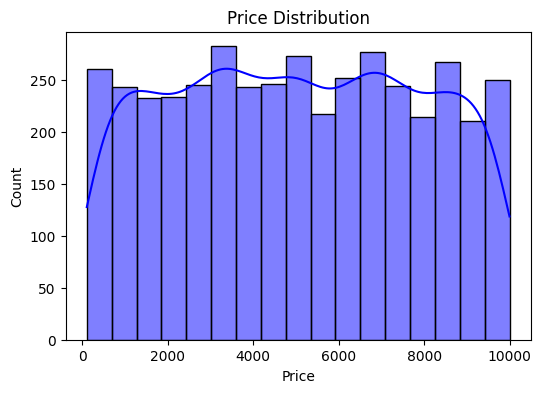

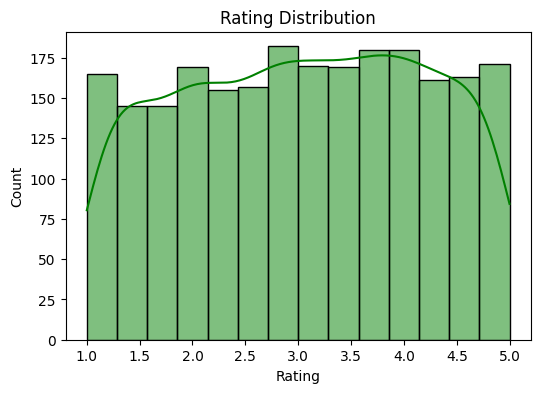

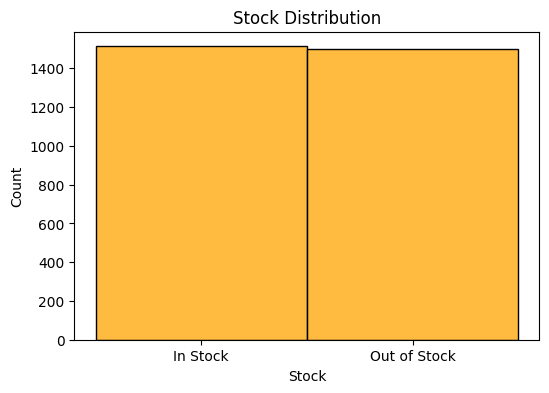

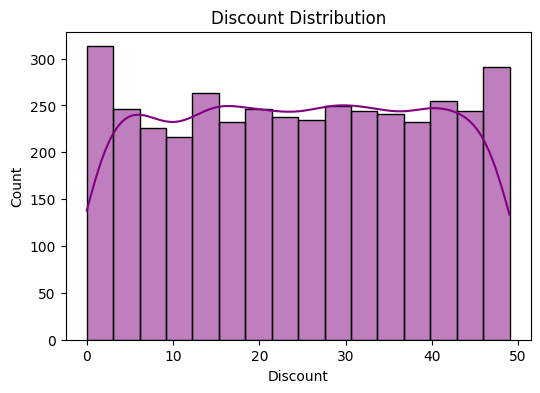

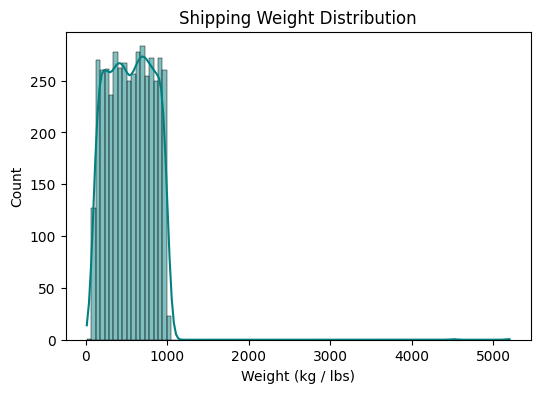

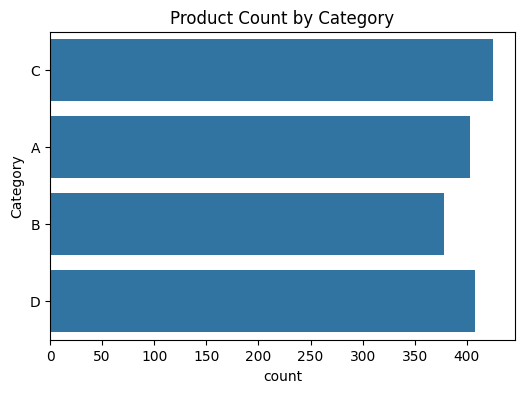

In [16]:
plt.figure(figsize=(6, 4))
sns.histplot(df['Price'], kde=True, color='blue')
plt.title('Price Distribution')
plt.show()

plt.figure(figsize=(6, 4))
sns.histplot(df['Rating'], kde=True, color='green')
plt.title('Rating Distribution')
plt.show()

plt.figure(figsize=(6, 4))
sns.histplot(df['Stock'], color='orange')
plt.title('Stock Distribution')
plt.show()

plt.figure(figsize=(6, 4))
sns.histplot(df['Discount'], kde=True, color='purple')
plt.title('Discount Distribution')
plt.show()

plt.figure(figsize=(6, 4))
sns.histplot(df['Shipping_weight'], kde=True, color='teal')
plt.title('Shipping Weight Distribution')
plt.xlabel('Weight (kg / lbs)')
plt.ylabel('Count')
plt.show()

# Distribution of the categorical feature
plt.figure(figsize=(6, 4))
sns.countplot(data=df, y='Category', order=df['Category'].value_index if hasattr(df['Category'], 'value_index') else None)
plt.title('Product Count by Category')
plt.show()

**2. bivariate analysis**

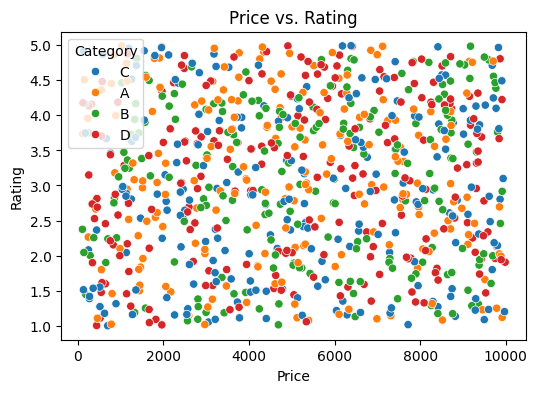

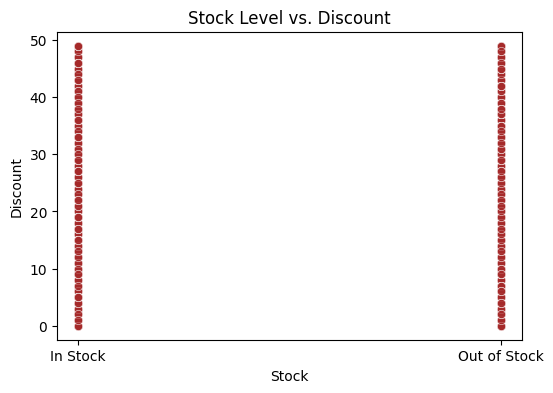

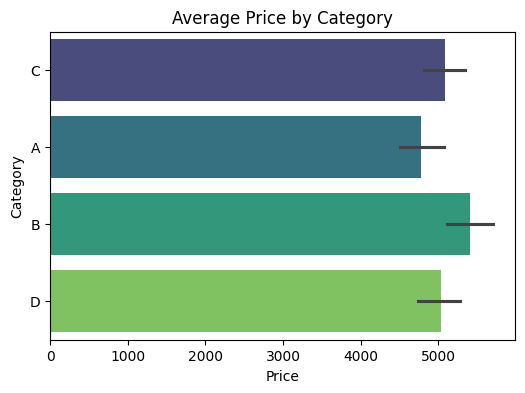

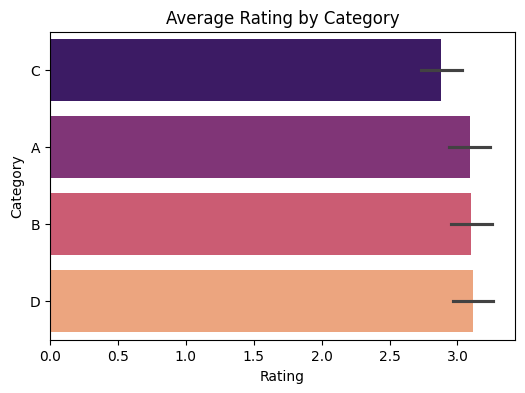

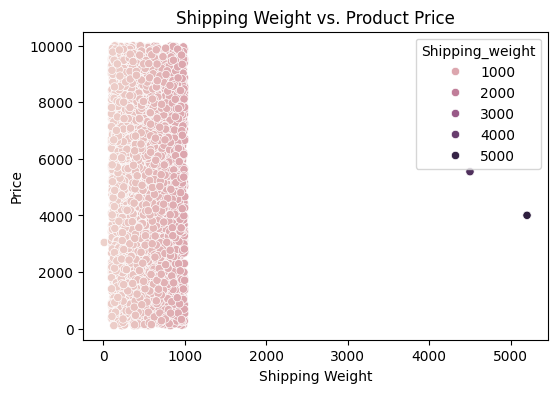

In [17]:
# Price vs Rating across different Categories(Numerical vs Numerical)
plt.figure(figsize=(6, 4))
sns.scatterplot(data=df, x='Price', y='Rating', hue='Category')
plt.title('Price vs. Rating')
plt.show()

# Stock vs Discount (Numerical vs Numerical)
plt.figure(figsize=(6, 4))
sns.scatterplot(data=df, x='Stock', y='Discount', color='brown', alpha=0.7)
plt.title('Stock Level vs. Discount')
plt.show()

# Average Price per Category 
plt.figure(figsize=(6, 4))
sns.barplot(data=df, x='Price', y='Category', hue='Category', palette='viridis', legend=False)
plt.title('Average Price by Category')
plt.show()

# Average Rating per Category 
plt.figure(figsize=(6, 4))
sns.barplot(data=df, x='Rating', y='Category', hue='Category', palette='magma', legend=False)
plt.title('Average Rating by Category')
plt.show()

#Shipping Weight vs. Price
plt.figure(figsize=(6, 4))
sns.scatterplot(data=df, x='Shipping_weight', y='Price', hue='Shipping_weight')
plt.title('Shipping Weight vs. Product Price')
plt.xlabel('Shipping Weight')
plt.ylabel('Price')
plt.show()


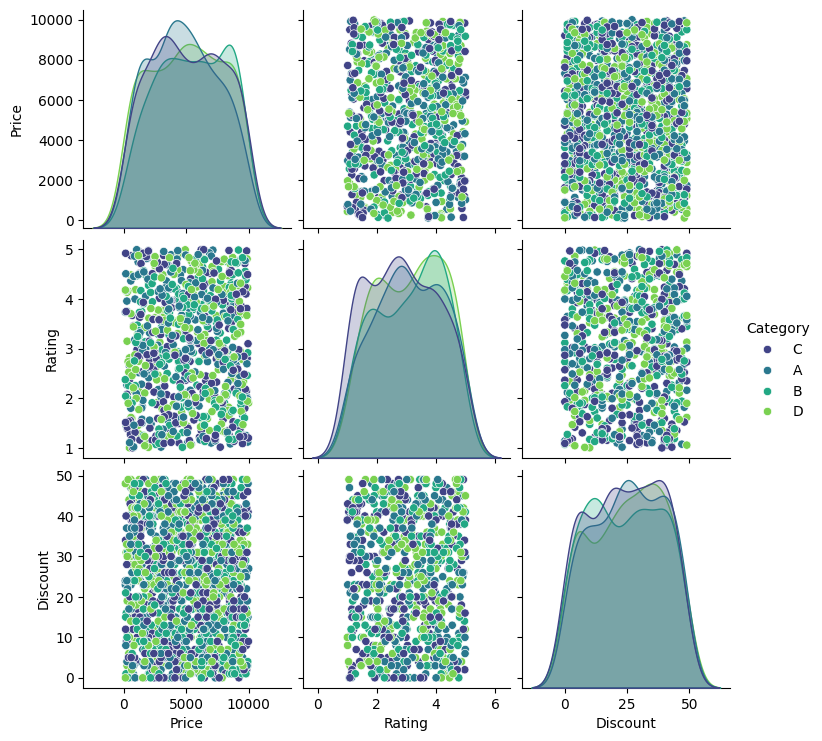

In [18]:
# Pairplot (Selected columns to save computation time)
sns.pairplot(df[['Category', 'Price', 'Rating', 'Stock', 'Discount']], hue='Category', palette='viridis')


**3. correlation analysis**

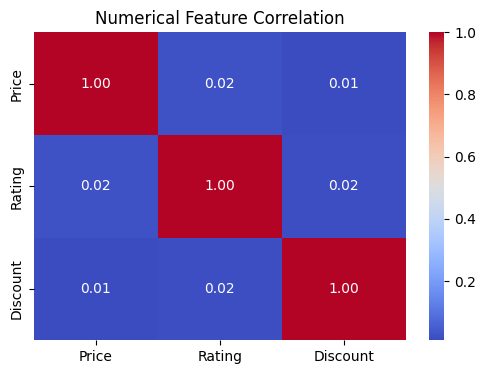

In [19]:
# Quick Correlation Matrix for numerical features
plt.figure(figsize=(6, 4))
sns.heatmap(df[['Price', 'Rating', 'Discount']].corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Numerical Feature Correlation')
plt.show()

#### **5. Data Cleaning**

**1. drop duplicates**

In [20]:
#remove duplicates
df = df.drop_duplicates()

**2. missing values**

In [21]:
df['Price'] = df['Price'].fillna(df['Price'].median())

**3. oulier detection**

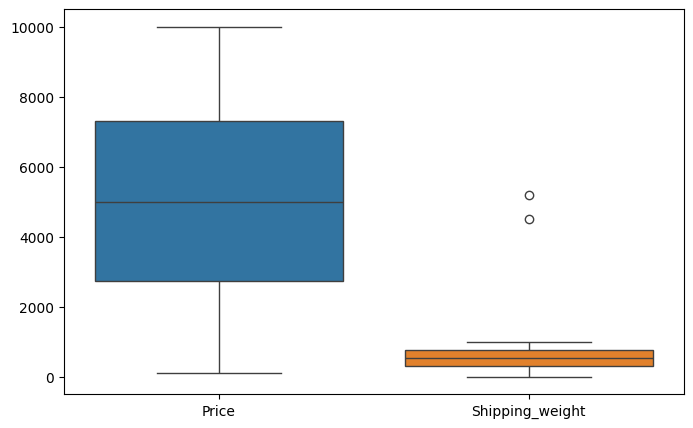

In [22]:
#Method 1: Box plot on Price and Value_Score
plt.figure(figsize=(8,5))
sns.boxplot(df[['Price','Shipping_weight']])
plt.show() # there no outliers in price


In [23]:
#------------------------------------------------------
# Method 2: IQR Method on Shipping_weight
Q1 = df["Shipping_weight"].quantile(0.25)
Q3 = df["Shipping_weight"].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
iqr_outliers = df[(df["Shipping_weight"] < lower_bound) | (df["Shipping_weight"] > upper_bound)]
print(f"IQR Method: Found {len(iqr_outliers)} outliers in Shipping_weight.")
print(f"Lower Bound Limit: {lower_bound:.2f} | Upper Bound Limit: {upper_bound:.2f}\n")

#clip instead remove
df["Shipping_weight"] = df["Shipping_weight"].clip(lower=lower_bound, upper=upper_bound)

print("--- DATASET CLEANING ---")
remaining_outliers = df[(df["Shipping_weight"] < lower_bound) | (df["Shipping_weight"] > upper_bound)]
print(f"Outliers remaining after clipping: {len(remaining_outliers)}")
print(f"Total dataset row count (Unchanged): {len(df)}")

IQR Method: Found 2 outliers in Shipping_weight.
Lower Bound Limit: -349.66 | Upper Bound Limit: 1446.43

--- DATASET CLEANING ---
Outliers remaining after clipping: 0
Total dataset row count (Unchanged): 4362


In [24]:
# Method 2: Z-score Method on Max HR
z_scores = np.abs(stats.zscore(df["Discount"]))
z_outliers = df[z_scores > 3]
print(f"Z-score Method: Found {len(z_outliers)} outliers in Discount.")


Z-score Method: Found 0 outliers in Discount.


#### **6. Feature Engineering**

In [25]:
df['Low_Stock_Alert'] = np.where(df['Stock'] == 'Out of Stock', 1, 0)

df['Popularity_Tier'] = np.where(df['Rating'] < 3, 1, 0 )

df['Value_Score'] = df['Rating'] * df['Discount']

#### **7. Train-test-split**

In [26]:
# Split features and labels
X = df.drop(columns=['Price','Popularity_Tier'])
y_reg = df["Price"]
y_cls = df["Popularity_Tier"]

# Regression Split
X_train, X_test, y_train_reg, y_test_reg = train_test_split(
    X, y_reg, test_size=0.2, random_state=42
)

# Classification Split
X_train, X_test, y_train_cls, y_test_cls = train_test_split(
    X, y_cls, test_size=0.2, random_state=42
)

#### **8. Pipeline**
Feature scaling & encoding

In [27]:
# feature categories
num_cols = ['Rating', 'Discount','Shipping_weight']
cat_cols = ['Category', 'Stock','Low_Stock_Alert']

# Create the preprocessor pipeline
num_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='mean')),
    ('scaler',StandardScaler())
])

cat_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer([
    ('num_processing', num_transformer, num_cols),
    ('cat_processing',cat_transformer, cat_cols)
])

X_train_array = preprocessor.fit_transform(X_train)
X_test_array = preprocessor.transform(X_test)

#Extract the correct processed column names from the preprocessor
feature_names = preprocessor.get_feature_names_out()

#Convert arrays back into Pandas DataFrames
X_train_advanced = pd.DataFrame(
    X_train_array, columns=feature_names, index=X_train.index
)
X_test_advanced = pd.DataFrame(
    X_test_array, columns=feature_names, index=X_test.index
)


#### **9. Train Regression Models**

In [28]:
# 1. Linear Regression 
lr_reg = LinearRegression()
lr_reg.fit(X_train_advanced, y_train_reg)

# 2. Ridge Regression 
rg_reg = Ridge()
rg_reg.fit(X_train_advanced, y_train_reg)

# 3. Lasso Regression 
ls_reg = Lasso()
ls_reg.fit(X_train_advanced, y_train_reg)

# 4. Decision Tree Regressor
dt_reg = DecisionTreeRegressor(random_state=42)
dt_reg.fit(X_train_advanced, y_train_reg)

# 5. Random Forest Regressor
rf_reg = RandomForestRegressor(random_state=42)
rf_reg.fit(X_train_advanced, y_train_reg)

# 6. Gradient Boosting Regressor
gb_reg = GradientBoostingRegressor(random_state=42)
gb_reg.fit(X_train_advanced, y_train_reg)

# 7. XGBoost Regressor
xg_reg = XGBRegressor(random_state=42)
xg_reg.fit(X_train_advanced, y_train_reg)

# 8. AdaBoost Regressor
ada_reg = AdaBoostRegressor(random_state=42)
ada_reg.fit(X_train_advanced, y_train_reg)

# 9. Support Vector Regressor
svm_reg = SVR(kernel='rbf')
svm_reg.fit(X_train_advanced, y_train_reg)

,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm.If none is given, 'rbf' will be used. If a callable is given it isused to precompute the kernel matrix.For an intuitive visualization of different kernel typessee :ref:`sphx_glr_auto_examples_svm_plot_svm_regression.py`",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive.The penalty is a squared l2. For an intuitive visualization of theeffects of scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"epsilon epsilon: float, default=0.1Epsilon in the epsilon-SVR model. It specifies the epsilon-tubewithin which no penalty is associated in the training loss functionwith points predicted within a distance epsilon from the actualvalue. Must be non-negative.",0.1
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide `.",True
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False
,"max_iter max_iter: int, default=-1Hard limit on iterations within solver, or -1 for no limit.",-1


#### **10. Regression Models Evaluation**

In [29]:
# 1. Linear Regression Evaluation
y_pred_lr = lr_reg.predict(X_test_advanced)
lr_mae = round(mean_absolute_error(y_test_reg, y_pred_lr), 4)
lr_mse = round(mean_squared_error(y_test_reg, y_pred_lr), 4)
lr_r2  = round(r2_score(y_test_reg, y_pred_lr) * 100, 2)

print("\n==========================================")
print("1. LINEAR REGRESSION PERFORMANCE")
print("----------+------------------------------")
print(f"MAE:       {lr_mae}")
print(f"MSE:       {lr_mse}")
print(f"R2 Score:  {lr_r2}%")


# 2. Ridge Regression Evaluation
y_pred_rg = rg_reg.predict(X_test_advanced)
rg_mae = round(mean_absolute_error(y_test_reg, y_pred_rg), 4)
rg_mse = round(mean_squared_error(y_test_reg, y_pred_rg), 4)
rg_r2  = round(r2_score(y_test_reg, y_pred_rg) * 100, 2)

print("\n==========================================")
print("2. RIDGE REGRESSION PERFORMANCE")
print("----------+------------------------------")
print(f"MAE:       {rg_mae}")
print(f"MSE:       {rg_mse}")
print(f"R2 Score:  {rg_r2}%")


# 3. Lasso Regression Evaluation
y_pred_ls = ls_reg.predict(X_test_advanced)
ls_mae = round(mean_absolute_error(y_test_reg, y_pred_ls), 4)
ls_mse = round(mean_squared_error(y_test_reg, y_pred_ls), 4)
ls_r2  = round(r2_score(y_test_reg, y_pred_ls) * 100, 2)

print("\n==========================================")
print("3. LASSO REGRESSION PERFORMANCE")
print("----------+------------------------------")
print(f"MAE:       {ls_mae}")
print(f"MSE:       {ls_mse}")
print(f"R2 Score:  {ls_r2}%")


# 4. Decision Tree Regressor Evaluation
y_pred_dt = dt_reg.predict(X_test_advanced)
dt_mae = round(mean_absolute_error(y_test_reg, y_pred_dt), 4)
dt_mse = round(mean_squared_error(y_test_reg, y_pred_dt), 4)
dt_r2  = round(r2_score(y_test_reg, y_pred_dt) * 100, 2)

print("\n==========================================")
print("4. DECISION TREE REGRESSOR PERFORMANCE")
print("----------+------------------------------")
print(f"MAE:       {dt_mae}")
print(f"MSE:       {dt_mse}")
print(f"R2 Score:  {dt_r2}%")


# 5. Random Forest Regressor Evaluation
y_pred_rf = rf_reg.predict(X_test_advanced)
rf_mae = round(mean_absolute_error(y_test_reg, y_pred_rf), 4)
rf_mse = round(mean_squared_error(y_test_reg, y_pred_rf), 4)
rf_r2  = round(r2_score(y_test_reg, y_pred_rf) * 100, 2)

print("\n==========================================")
print("5. RANDOM FOREST REGRESSOR PERFORMANCE")
print("----------+------------------------------")
print(f"MAE:       {rf_mae}")
print(f"MSE:       {rf_mse}")
print(f"R2 Score:  {rf_r2}%")


# 6. Gradient Boosting Regressor Evaluation
y_pred_gb = gb_reg.predict(X_test_advanced)
gb_mae = round(mean_absolute_error(y_test_reg, y_pred_gb), 4)
gb_mse = round(mean_squared_error(y_test_reg, y_pred_gb), 4)
gb_r2  = round(r2_score(y_test_reg, y_pred_gb) * 100, 2)

print("\n==========================================")
print("6. GRADIENT BOOSTING REGRESSOR PERFORMANCE")
print("----------+------------------------------")
print(f"MAE:       {gb_mae}")
print(f"MSE:       {gb_mse}")
print(f"R2 Score:  {gb_r2}%")


# 7. XGBoost Regressor Evaluation
y_pred_xg = xg_reg.predict(X_test_advanced)
xg_mae = round(mean_absolute_error(y_test_reg, y_pred_xg), 4)
xg_mse = round(mean_squared_error(y_test_reg, y_pred_xg), 4)
xg_r2  = round(r2_score(y_test_reg, y_pred_xg) * 100, 2)

print("\n==========================================")
print("7. XGBOOST REGRESSOR PERFORMANCE")
print("----------+------------------------------")
print(f"MAE:       {xg_mae}")
print(f"MSE:       {xg_mse}")
print(f"R2 Score:  {xg_r2}%")


# 8. AdaBoost Regressor Evaluation
y_pred_ada = ada_reg.predict(X_test_advanced)
ada_mae = round(mean_absolute_error(y_test_reg, y_pred_ada), 4)
ada_mse = round(mean_squared_error(y_test_reg, y_pred_ada), 4)
ada_r2  = round(r2_score(y_test_reg, y_pred_ada) * 100, 2)

print("\n==========================================")
print("8. ADABOOST REGRESSOR PERFORMANCE")
print("----------+------------------------------")
print(f"MAE:       {ada_mae}")
print(f"MSE:       {ada_mse}")
print(f"R2 Score:  {ada_r2}%")


# 9. Support Vector Regressor Evaluation
y_pred_svm = svm_reg.predict(X_test_advanced)
svm_mae = round(mean_absolute_error(y_test_reg, y_pred_svm), 4)
svm_mse = round(mean_squared_error(y_test_reg, y_pred_svm), 4)
svm_r2  = round(r2_score(y_test_reg, y_pred_svm) * 100, 2)

print("\n==========================================")
print("9. SUPPORT VECTOR REGRESSOR PERFORMANCE")
print("----------+------------------------------")
print(f"MAE:       {svm_mae}")
print(f"MSE:       {svm_mse}")
print(f"R2 Score:  {svm_r2}%")


1. LINEAR REGRESSION PERFORMANCE
----------+------------------------------
MAE:       2389.2041
MSE:       7948523.5695
R2 Score:  -0.57%

2. RIDGE REGRESSION PERFORMANCE
----------+------------------------------
MAE:       2389.1936
MSE:       7948469.9334
R2 Score:  -0.57%

3. LASSO REGRESSION PERFORMANCE
----------+------------------------------
MAE:       2388.9965
MSE:       7947190.6808
R2 Score:  -0.55%

4. DECISION TREE REGRESSOR PERFORMANCE
----------+------------------------------
MAE:       3305.8912
MSE:       16324304.2383
R2 Score:  -106.54%

5. RANDOM FOREST REGRESSOR PERFORMANCE
----------+------------------------------
MAE:       2505.9495
MSE:       9083806.8314
R2 Score:  -14.93%

6. GRADIENT BOOSTING REGRESSOR PERFORMANCE
----------+------------------------------
MAE:       2405.7762
MSE:       8096188.8636
R2 Score:  -2.44%

7. XGBOOST REGRESSOR PERFORMANCE
----------+------------------------------
MAE:       2591.6829
MSE:       9673406.0035
R2 Score:  -22.39%

8

**Model accuracy comparision**

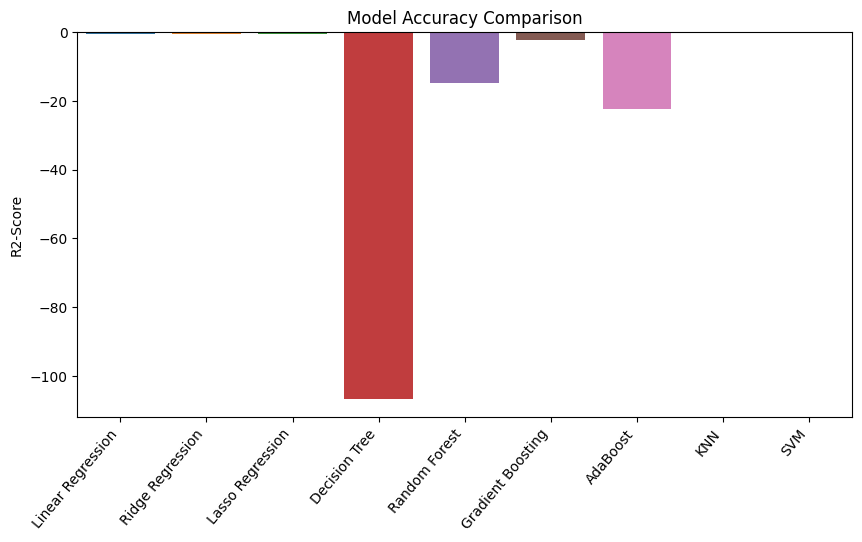

In [30]:
r2 = [lr_r2,rg_r2,ls_r2,dt_r2,rf_r2,gb_r2,xg_r2,ada_r2,svm_r2]
algorithms = ["Linear Regression","Ridge Regression","Lasso Regression","Decision Tree","Random Forest","Gradient Boosting","AdaBoost","KNN","SVM"]    

# accuracy score
plt.figure(figsize=(10, 5))
sns.barplot(x=algorithms,y=r2,hue=algorithms)
plt.xticks(rotation=50, ha='right')
plt.ylabel("R2-Score")
plt.title("Model Accuracy Comparison")
plt.show()

#### **11. Train Classification Models**

In [31]:
# 1. Logistic Regression
lr_cls = LogisticRegression(max_iter=1000)
lr_cls.fit(X_train_advanced, y_train_cls)

# 2. Decision Tree Classifier
dt_cls = DecisionTreeClassifier(random_state=42)
dt_cls.fit(X_train_advanced, y_train_cls)

# 3. Random Forest Classifier
rf_cls = RandomForestClassifier(random_state=42)
rf_cls.fit(X_train_advanced, y_train_cls)

# 4. Gradient Boosting Classifier
gb_cls = GradientBoostingClassifier(random_state=42)
gb_cls.fit(X_train_advanced, y_train_cls)

# 5. XGBoost Classifier
xg_cls = XGBClassifier(random_state=42)
xg_cls.fit(X_train_advanced, y_train_cls)

# 6. AdaBoost Classifier
ada_cls = AdaBoostClassifier(random_state=42)
ada_cls.fit(X_train_advanced, y_train_cls)

# 7. KNN Classifier
knn_cls = KNeighborsClassifier()
knn_cls.fit(X_train_advanced, y_train_cls)

# 8. Support Vector Classifier
svm_cls = SVC(probability=True, random_state=42)
svm_cls.fit(X_train_advanced, y_train_cls)

# 9. Naive Bayes Classifier
nb_cls = GaussianNB()
nb_cls.fit(X_train_advanced, y_train_cls)

,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",1e-09


#### **12. Classification Models Evalution**

In [32]:
# 1. Logistic Regression
y_pred_lr = lr_cls.predict(X_test_advanced)
lr_score = round(accuracy_score(y_test_cls, y_pred_lr)*100,2)
lr_f1 = round(f1_score(y_test_cls, y_pred_lr)*100,2)
lr_precision = round(precision_score(y_test_cls, y_pred_lr)*100,2)
lr_recall = round(recall_score(y_test_cls, y_pred_lr)*100,2)
cm_lr = confusion_matrix(y_test_cls, y_pred_lr)

print("\n==========================================")
print("1. LOGISTIC REGRESSION PERFORMANCE")
print("------------------+-----------------------")
print(f"Accuracy:          {lr_score}%")
print(f"F1-Score:          {lr_f1}%")
print(f"Precision:         {lr_precision}%")
print(f"Recall:            {lr_recall}%")
print("Confusion Matrix:\n", cm_lr)
print("Classification Report:\n", classification_report(y_test_cls, y_pred_lr))

# ==========================================
# 2. Decision Tree
y_pred_dt = dt_cls.predict(X_test_advanced)
dt_score = round(accuracy_score(y_test_cls, y_pred_dt) * 100, 2)
dt_f1 = round(f1_score(y_test_cls, y_pred_dt) * 100, 2)
dt_precision = round(precision_score(y_test_cls, y_pred_dt) * 100, 2)
dt_recall = round(recall_score(y_test_cls, y_pred_dt) * 100, 2)
cm_dt = confusion_matrix(y_test_cls, y_pred_dt)

print("\n==========================================")
print("2. DECISION TREE PERFORMANCE")
print("------------------+-----------------------")
print(f"Accuracy:          {dt_score}%")
print(f"F1-Score:          {dt_f1}%")
print(f"Precision:         {dt_precision}%")
print(f"Recall:            {dt_recall}%")
print("Confusion Matrix:\n", cm_dt)
print("Classification Report:\n", classification_report(y_test_cls, y_pred_dt))


# ==========================================
# 3. Random Forest
y_pred_rf = rf_cls.predict(X_test_advanced)
rf_score = round(accuracy_score(y_test_cls, y_pred_rf) * 100, 2)
rf_f1 = round(f1_score(y_test_cls, y_pred_rf) * 100, 2)
rf_precision = round(precision_score(y_test_cls, y_pred_rf) * 100, 2)
rf_recall = round(recall_score(y_test_cls, y_pred_rf) * 100, 2)
cm_rf = confusion_matrix(y_test_cls, y_pred_rf)

print("\n==========================================")
print("3. RANDOM FOREST PERFORMANCE")
print("------------------+-----------------------")
print(f"Accuracy:          {rf_score}%")
print(f"F1-Score:          {rf_f1}%")
print(f"Precision:         {rf_precision}%")
print(f"Recall:            {rf_recall}%")
print("Confusion Matrix:\n", cm_rf)
print("Classification Report:\n", classification_report(y_test_cls, y_pred_rf))

# ==========================================
# 4. Gradient Boosting
y_pred_gb = gb_cls.predict(X_test_advanced)
gb_score = round(accuracy_score(y_test_cls, y_pred_gb) * 100, 2)
gb_f1 = round(f1_score(y_test_cls, y_pred_gb) * 100, 2)
gb_precision = round(precision_score(y_test_cls, y_pred_gb) * 100, 2)
gb_recall = round(recall_score(y_test_cls, y_pred_gb) * 100, 2)
cm_gb = confusion_matrix(y_test_cls, y_pred_gb)

print("\n==========================================")
print("4. GRADIENT BOOSTING PERFORMANCE")
print("------------------+-----------------------")
print(f"Accuracy:          {gb_score}%")
print(f"F1-Score:          {gb_f1}%")
print(f"Precision:         {gb_precision}%")
print(f"Recall:            {gb_recall}%")
print("Confusion Matrix:\n", cm_gb)
print("Classification Report:\n", classification_report(y_test_cls, y_pred_gb))

# ==========================================
# 5. XgBoosting
y_pred_xg = xg_cls.predict(X_test_advanced)
xg_score = round(accuracy_score(y_test_cls, y_pred_xg) * 100, 2)
xg_f1 = round(f1_score(y_test_cls, y_pred_xg) * 100, 2)
xg_precision = round(precision_score(y_test_cls, y_pred_xg) * 100, 2)
xg_recall = round(recall_score(y_test_cls, y_pred_xg) * 100, 2)
cm_xg = confusion_matrix(y_test_cls, y_pred_xg)

print("\n==========================================")
print("5. GRADIENT BOOSTING PERFORMANCE")
print("------------------+-----------------------")
print(f"Accuracy:          {xg_score}%")
print(f"F1-Score:          {xg_f1}%")
print(f"Precision:         {xg_precision}%")
print(f"Recall:            {xg_recall}%")
print("Confusion Matrix:\n", cm_xg)
print("Classification Report:\n", classification_report(y_test_cls, y_pred_xg))

# ==========================================
# 6. AdaBoost
y_pred_ada = ada_cls.predict(X_test_advanced)
ada_score = round(accuracy_score(y_test_cls, y_pred_ada) * 100, 2)
ada_f1 = round(f1_score(y_test_cls, y_pred_ada) * 100, 2)
ada_precision = round(precision_score(y_test_cls, y_pred_ada) * 100, 2)
ada_recall = round(recall_score(y_test_cls, y_pred_ada) * 100, 2)
cm_ada = confusion_matrix(y_test_cls, y_pred_ada)

print("\n==========================================")
print("6. ADABOOST PERFORMANCE")
print("------------------+-----------------------")
print(f"Accuracy:          {ada_score}%")
print(f"F1-Score:          {ada_f1}%")
print(f"Precision:         {ada_precision}%")
print(f"Recall:            {ada_recall}%")
print("Confusion Matrix:\n", cm_ada)
print("Classification Report:\n", classification_report(y_test_cls, y_pred_ada))


# ==========================================
# 7. KNN
y_pred_knn = knn_cls.predict(X_test_advanced)
knn_score = round(accuracy_score(y_test_cls, y_pred_knn) * 100, 2)
knn_f1 = round(f1_score(y_test_cls, y_pred_knn) * 100, 2)
knn_precision = round(precision_score(y_test_cls, y_pred_knn) * 100, 2)
knn_recall = round(recall_score(y_test_cls, y_pred_knn) * 100, 2)
cm_knn = confusion_matrix(y_test_cls, y_pred_knn)

print("\n==========================================")
print("7. KNN PERFORMANCE")
print("------------------+-----------------------")
print(f"Accuracy:          {knn_score}%")
print(f"F1-Score:          {knn_f1}%")
print(f"Precision:         {knn_precision}%")
print(f"Recall:            {knn_recall}%")
print("Confusion Matrix:\n", cm_knn)
print("Classification Report:\n", classification_report(y_test_cls, y_pred_knn))


# ==========================================
# 8. SVM
y_pred_svm = svm_cls.predict(X_test_advanced)
svm_score = round(accuracy_score(y_test_cls, y_pred_svm) * 100, 2)
svm_f1 = round(f1_score(y_test_cls, y_pred_svm) * 100, 2)
svm_precision = round(precision_score(y_test_cls, y_pred_svm) * 100, 2)
svm_recall = round(recall_score(y_test_cls, y_pred_svm) * 100, 2)
cm_svm = confusion_matrix(y_test_cls, y_pred_svm)

print("\n==========================================")
print("8. SVM PERFORMANCE")
print("------------------+-----------------------")
print(f"Accuracy:          {svm_score}%")
print(f"F1-Score:          {svm_f1}%")
print(f"Precision:         {svm_precision}%")
print(f"Recall:            {svm_recall}%")
print("Confusion Matrix:\n", cm_svm)
print("Classification Report:\n", classification_report(y_test_cls, y_pred_svm))


# ==========================================
# 9. Naive Bayes
y_pred_nb = nb_cls.predict(X_test_advanced)
nb_score = round(accuracy_score(y_test_cls, y_pred_nb) * 100, 2)
nb_f1 = round(f1_score(y_test_cls, y_pred_nb) * 100, 2)
nb_precision = round(precision_score(y_test_cls, y_pred_nb) * 100, 2)
nb_recall = round(recall_score(y_test_cls, y_pred_nb) * 100, 2)
cm_nb = confusion_matrix(y_test_cls, y_pred_nb)

print("\n==========================================")
print("9. NAIVE BAYES PERFORMANCE")
print("------------------+-----------------------")
print(f"Accuracy:          {nb_score}%")
print(f"F1-Score:          {nb_f1}%")
print(f"Precision:         {nb_precision}%")
print(f"Recall:            {nb_recall}%")
print("Confusion Matrix:\n", cm_nb)
print("Classification Report:\n", classification_report(y_test_cls, y_pred_nb))


1. LOGISTIC REGRESSION PERFORMANCE
------------------+-----------------------
Accuracy:          98.17%
F1-Score:          96.17%
Precision:         100.0%
Recall:            92.63%
Confusion Matrix:
 [[656   0]
 [ 16 201]]
Classification Report:
               precision    recall  f1-score   support

           0       0.98      1.00      0.99       656
           1       1.00      0.93      0.96       217

    accuracy                           0.98       873
   macro avg       0.99      0.96      0.97       873
weighted avg       0.98      0.98      0.98       873


2. DECISION TREE PERFORMANCE
------------------+-----------------------
Accuracy:          100.0%
F1-Score:          100.0%
Precision:         100.0%
Recall:            100.0%
Confusion Matrix:
 [[656   0]
 [  0 217]]
Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00       656
           1       1.00      1.00      1.00       217

    accuracy     

**Model accuracy comparision**

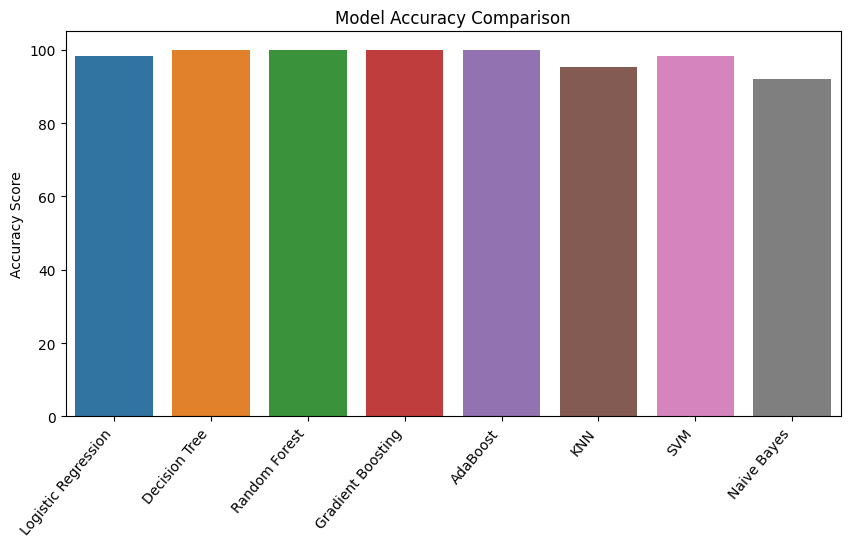

In [33]:
scores = [lr_score,dt_score,rf_score,gb_score,ada_score,knn_score,svm_score,nb_score]
f1 = [lr_f1,dt_f1,rf_f1,gb_f1,ada_f1,knn_f1,svm_f1,nb_f1]
algorithms = ["Logistic Regression","Decision Tree","Random Forest","Gradient Boosting","AdaBoost","KNN","SVM","Naive Bayes"]    

# accuracy score
plt.figure(figsize=(10, 5))
sns.barplot(x=algorithms,y=scores,hue=algorithms)
plt.xticks(rotation=50, ha='right')
plt.ylabel("Accuracy Score")
plt.title("Model Accuracy Comparison")
plt.show()

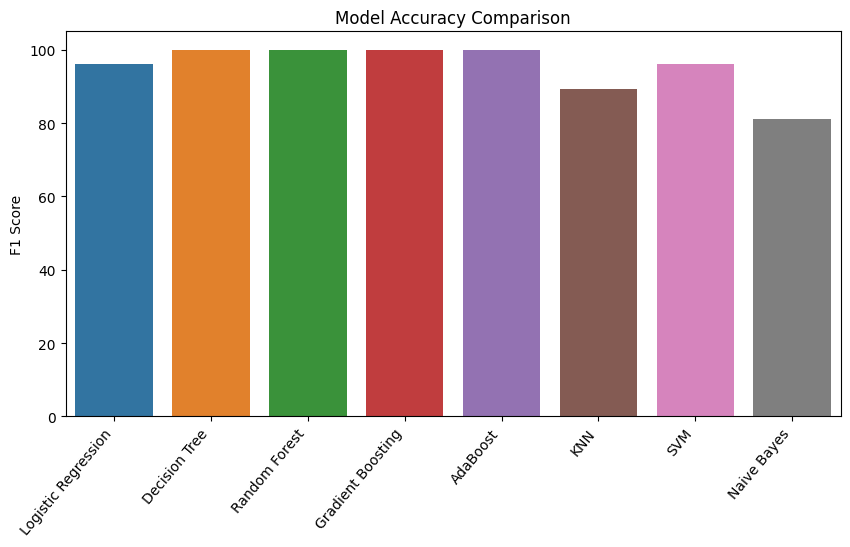

In [34]:
# f1 score
plt.figure(figsize=(10, 5))
sns.barplot(x=algorithms,y=f1,hue=algorithms)
plt.xticks(rotation=50, ha='right')
plt.ylabel("F1 Score")
plt.title("Model Accuracy Comparison")
plt.show()

#### **13. Cross Validation**

In [35]:
print("\n--- 5-FOLD CROSS VALIDATION (ACCURACY %) ---")

# 1. Logistic Regression CV
lr_cv = cross_val_score(lr_cls, X_train_advanced, y_train_cls, cv=5, scoring="accuracy")
print(f"Logistic Regression Mean CV: {round(lr_cv.mean() * 100, 2)}% (+/- {round(lr_cv.std() * 100, 2)}%)")

# 2. Decision Tree CV
dt_cv = cross_val_score(dt_cls, X_train_advanced, y_train_cls, cv=5, scoring="accuracy")
print(f"Decision Tree Mean CV:       {round(dt_cv.mean() * 100, 2)}% (+/- {round(dt_cv.std() * 100, 2)}%)")

# 3. Random Forest CV
rf_cv = cross_val_score(rf_cls, X_train_advanced, y_train_cls, cv=5, scoring="accuracy")
print(f"Random Forest Mean CV:       {round(rf_cv.mean() * 100, 2)}% (+/- {round(rf_cv.std() * 100, 2)}%)")

# 4. Gradient Boosting CV
gb_cv = cross_val_score(gb_cls, X_train_advanced, y_train_cls, cv=5, scoring="accuracy")
print(f"Gradient Boosting Mean CV:   {round(gb_cv.mean() * 100, 2)}% (+/- {round(gb_cv.std() * 100, 2)}%)")

# 5. AdaBoost CV
ada_cv = cross_val_score(ada_cls, X_train_advanced, y_train_cls, cv=5, scoring="accuracy")
print(f"AdaBoost Mean CV:            {round(ada_cv.mean() * 100, 2)}% (+/- {round(ada_cv.std() * 100, 2)}%)")

# 6. KNN CV
knn_cv = cross_val_score(knn_cls, X_train_advanced, y_train_cls, cv=5, scoring="accuracy")
print(f"KNN Mean CV:                 {round(knn_cv.mean() * 100, 2)}% (+/- {round(knn_cv.std() * 100, 2)}%)")

# 7. SVM CV
svm_cv = cross_val_score(svm_cls, X_train_advanced, y_train_cls, cv=5, scoring="accuracy")
print(f"SVM Mean CV:                 {round(svm_cv.mean() * 100, 2)}% (+/- {round(svm_cv.std() * 100, 2)}%)")

# 8. Naive Bayes CV
nb_cv = cross_val_score(nb_cls, X_train_advanced, y_train_cls, cv=5, scoring="accuracy")
print(f"Naive Bayes Mean CV:         {round(nb_cv.mean() * 100, 2)}% (+/- {round(nb_cv.std() * 100, 2)}%)")


--- 5-FOLD CROSS VALIDATION (ACCURACY %) ---
Logistic Regression Mean CV: 97.53% (+/- 0.78%)
Decision Tree Mean CV:       99.97% (+/- 0.06%)
Random Forest Mean CV:       99.94% (+/- 0.11%)
Gradient Boosting Mean CV:   99.97% (+/- 0.06%)
AdaBoost Mean CV:            99.97% (+/- 0.06%)
KNN Mean CV:                 94.27% (+/- 0.94%)
SVM Mean CV:                 97.45% (+/- 0.77%)
Naive Bayes Mean CV:         92.35% (+/- 0.8%)


#### **14. Feature Selection**

In [36]:
print("\n--- FEATURE SELECTION ---")

# 1.Variance Threshold -> Checks low-variance features on your raw unscaled training columns
selector_vt = VarianceThreshold(threshold=0.1)
X_vt = selector_vt.fit_transform(X_train_advanced)
print(f"Variance Threshold: Reduced columns shape to {X_vt.shape}")

# Get names of columns that pass the threshold
vt_names = X_train_advanced.columns[selector_vt.get_support()].tolist()
print("Variance Threshold Features:", vt_names)
#----

# 2. Pick top 5 columns using Chi-Square (for classification)
X_positive = MinMaxScaler().fit_transform(X_train_advanced)
selector_kb = SelectKBest(score_func=chi2, k=5)
X_kb = selector_kb.fit_transform(X_positive, y_train_cls)
print(f"\nSelectKBest (Chi-Square): Selected top 5 columns shape to {X_kb.shape}")

# Get names of the top 5 classification features
kb_names = X_train_advanced.columns[selector_kb.get_support()].tolist()
print("SelectKBest Top 5 Features:", kb_names)
#----

# 3. Pick top 5 columns using RFE elimination (for regression)
rfe = RFE(estimator=LinearRegression(), n_features_to_select=5)
X_rfe = rfe.fit_transform(X_train_advanced, y_train_reg)
print(f"\nRFE: Extracted top 5 features shape to {X_rfe.shape}")

# Map chosen columns back to our combined advanced features list
rfe_names = X_train_advanced.columns[rfe.support_].tolist()
print("RFE Top 5 Regressor Features:", rfe_names)
#----

# Compress all columns down to 2 principal components
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_train_advanced)
print(f"\nPCA shape: {X_pca.shape}")
print(f"PCA explained variance ratio: {pca.explained_variance_ratio_}")



--- FEATURE SELECTION ---
Variance Threshold: Reduced columns shape to (3489, 8)
Variance Threshold Features: ['num_processing__Rating', 'num_processing__Discount', 'num_processing__Shipping_weight', 'cat_processing__Category_C', 'cat_processing__Stock_In Stock', 'cat_processing__Stock_Out of Stock', 'cat_processing__Low_Stock_Alert_0', 'cat_processing__Low_Stock_Alert_1']

SelectKBest (Chi-Square): Selected top 5 columns shape to (3489, 5)
SelectKBest Top 5 Features: ['num_processing__Rating', 'cat_processing__Category_B', 'cat_processing__Category_C', 'cat_processing__Stock_Out of Stock', 'cat_processing__Low_Stock_Alert_1']

RFE: Extracted top 5 features shape to (3489, 5)
RFE Top 5 Regressor Features: ['num_processing__Shipping_weight', 'cat_processing__Category_A', 'cat_processing__Category_B', 'cat_processing__Category_C', 'cat_processing__Stock_Out of Stock']

PCA shape: (3489, 2)
PCA explained variance ratio: [0.2371839  0.23072998]


#### **15. Hyperparameter Tuning**

In [37]:

#Combine preprocessing and the model into a master pipeline
full_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', RandomForestRegressor(random_state=42))
])

rf_param_grid = {
    'regressor__n_estimators': [100,200,300],
    'regressor__max_depth': [3, 5, 10]
}

rf_grid = GridSearchCV(
    estimator=full_pipeline,
    param_grid=rf_param_grid,
    cv=3,                 # 3-fold cross-validation keeps it fast
    scoring='r2',
    n_jobs=-1
)

rf_grid.fit(X_train,y_train_reg)
print("\n--- HYPERPARAMETER TUNING (Random Forest) ---")
print("Best Grid Search Params:", rf_grid.best_params_)
print("Best Grid Search R²:", round(rf_grid.best_score_, 4))


--- HYPERPARAMETER TUNING (Random Forest) ---
Best Grid Search Params: {'regressor__max_depth': 3, 'regressor__n_estimators': 300}
Best Grid Search R²: -0.0015


In [38]:

# Combine preprocessing and the model into a master pipeline
full_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(random_state=42))
])

rf_param_randomized = {
    'classifier__n_estimators': [100,200,300],
    'classifier__max_depth': [3, 5, 10]
}

rf_randomized = RandomizedSearchCV(
    estimator=full_pipeline,
    param_distributions=rf_param_randomized, 
    n_iter=5, 
    cv=3, 
    scoring="accuracy", 
    random_state=42)

rf_randomized.fit(X_train,y_train_cls)
print("\n--- HYPERPARAMETER TUNING (Random Forest) ---")
print("Best Randomized search Params:", rf_grid.best_params_)
print("Best Randomized search accuracy:", round(rf_grid.best_score_, 4))


--- HYPERPARAMETER TUNING (Random Forest) ---
Best Randomized search Params: {'regressor__max_depth': 3, 'regressor__n_estimators': 300}
Best Randomized search accuracy: -0.0015


#### **16. Feature Importance**


--- TOP FEATURE IMPORTANCE SCORES ---
                           Feature  Importance
   num_processing__Shipping_weight    0.433608
          num_processing__Discount    0.242758
            num_processing__Rating    0.216899
        cat_processing__Category_C    0.020343
        cat_processing__Category_D    0.016418
        cat_processing__Category_A    0.013753
        cat_processing__Category_B    0.011944
 cat_processing__Low_Stock_Alert_0    0.011361
 cat_processing__Low_Stock_Alert_1    0.011034
cat_processing__Stock_Out of Stock    0.011032
    cat_processing__Stock_In Stock    0.010850


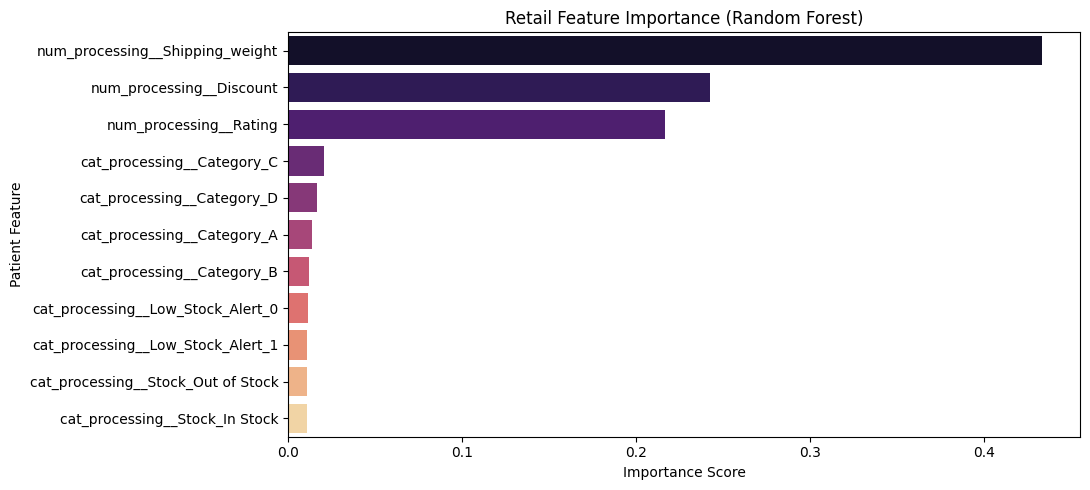

In [39]:
# Reconstruct the exact order of column names as they exist in X_train_advanced(Remember: np.hstack put numeric columns first, then categorical columns!)
advanced_columns = X_train_advanced.columns.tolist()

importance = pd.DataFrame({
    'Feature': advanced_columns,
    'Importance': rf_reg.feature_importances_
})

#  THE FIX: Permanently sort the DataFrame in descending order
importance = importance.sort_values(by='Importance', ascending=False)

print("\n--- TOP FEATURE IMPORTANCE SCORES ---")
print(importance.to_string(index=False))

plt.figure(figsize=(11, 5))
sns.barplot(
    data=importance,  # Now Seaborn reads the perfectly sorted rows!
    x="Importance",
    y="Feature",
    palette="magma",
    hue="Feature"
)
plt.title("Retail Feature Importance (Random Forest)")
plt.xlabel("Importance Score")
plt.ylabel("Patient Feature")
plt.tight_layout()
plt.show()

#### **18. Production Pipeline**

In [40]:
production_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', RandomForestRegressor(n_estimators=200, max_depth=10, random_state=42))
])

# 4. FIT ON THE RAW TRAINING DATA-> pipeline handles .fit_transform() internally for features right before training
production_pipeline.fit(X_train, y_train_reg)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num_processing', ...), ('cat_processing', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the dif

#### **18. Save model**

In [41]:
#SERIALIZE AND EXPORT THE PIPELINE
joblib.dump(production_pipeline, "retail_production_model.pkl")
print("Production pipeline successfully exported!")

Production pipeline successfully exported!


**and Load Model**

In [42]:
#Test loading back the exact pipeline structure
loaded_pipeline = joblib.load("retail_production_model.pkl")
print("Pipeline loaded successfully! Ready for real-world predictions.")

Pipeline loaded successfully! Ready for real-world predictions.


`Easy Flow to Remember`

1. Import Libraries
2. Load Dataset
EDA:
3. understand your data -> head(),shape,info(),df.describe(),dtypes,target variable analysis
4. Data Cleaning -> remove duplicates & unwanted, handle missing values, Fix data types, Outliers detection
5. Feature Engineering -> Create/transform features, encode categories if needed
6. Data Visualization -> univariate(histogram, countplot, boxplot), bivariate AnalysisBivariate analysis (scatterplot, pairplot, heatmap)  


7. Define Features (X) and Target (y)
8. Train-Test Split 

9. Preprocessing Pipeline -> imputation, encoding, scaling, column_transformer `before training`

Train Models:

10. Regression Models
11. Regression Metrics

Evaluate Models:

12. Classification Models
13. Classification Metrics 

14. Cross Validation
15. Feature Selection -> Correlation-based, SelectKBest, Recursive Feature Elimination (RFE), Lasso feature selection `before training`
16. Hyperparameter Tuning -> GridSearchCV, RandomizedSearchCV
17. Feature Importance -> Random Forest feature importance, XGBoost importance, SHAP values (advanced)
18. Final Pipeline Production -> Combine preprocessing + best model into one pipeline.

19. Save Model & load model
20. Deployment (Streamlit / Flask / FastAPI)

Build Preprocessing Pipeline = `Prepare the data`
Final Pipeline = `Prepare the data` + `Make predictions` -> This combines preprocessing + trained model into a single pipeline so that new data can be predicted directly.

In [43]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12,6))

ax = sns.barplot(
    x=algorithms,
    y=r2,
    palette="viridis"
)

plt.axhline(0, color='black')

for i, v in enumerate(r2):
    ax.text(i, v, f"{v:.2f}", ha='center',
            va='bottom' if v>=0 else 'top',
            fontsize=10)

plt.title("R² Score Comparison")
plt.xlabel("Models")
plt.ylabel("R² Score")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

ValueError: All arrays must be of the same length

<Figure size 1200x600 with 0 Axes>